In [1]:
# ============================================================
# 04.03 — PROBABILITY ANALYSIS
# CELL 1 — IMPORTS
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    log_loss
)

from sklearn.calibration import calibration_curve


print("=" * 60)
print("04.03 PROBABILITY ANALYSIS")
print("=" * 60)

print(f"PyTorch version : {torch.__version__}")
print(f"NumPy version   : {np.__version__}")
print(f"Device          : {'cuda' if torch.cuda.is_available() else 'cpu'}")

04.03 PROBABILITY ANALYSIS
PyTorch version : 2.13.0+cpu
NumPy version   : 2.5.2
Device          : cpu


In [2]:
# ============================================================
# CELL 2 — PATHS AND REPRODUCIBILITY
# ============================================================

PROJECT_ROOT = r"C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening"

CROSS_MODAL_ROOT = os.path.join(
    PROJECT_ROOT,
    "06_cross_modal_learning"
)

PHASE_02_08_ROOT = os.path.join(
    CROSS_MODAL_ROOT,
    "02_cross_modal_pairing",
    "pairs",
    "representation_aware_split"
)

BASELINE_ROOT = os.path.join(
    CROSS_MODAL_ROOT,
    "03_cross_modal_learning",
    "03_04_baseline_training"
)

EVALUATION_ROOT = os.path.join(
    CROSS_MODAL_ROOT,
    "04_cross_modal_evaluation"
)

FIGURES_DIR = os.path.join(
    EVALUATION_ROOT,
    "figures"
)

REPORTS_DIR = os.path.join(
    EVALUATION_ROOT,
    "reports"
)

CHECKPOINT_PATH = os.path.join(
    BASELINE_ROOT,
    "checkpoints",
    "03_04_baseline_best_model.pt"
)

TRAIN_PAIRS_PATH = os.path.join(
    PHASE_02_08_ROOT,
    "02_08_train_representation_disjoint_pairs.npz"
)

VALIDATION_PAIRS_PATH = os.path.join(
    PHASE_02_08_ROOT,
    "02_08_validation_representation_disjoint_pairs.npz"
)

VALIDATION_METADATA_PATH = os.path.join(
    PHASE_02_08_ROOT,
    "02_08_validation_representation_disjoint_metadata.csv"
)

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project root:")
print(PROJECT_ROOT)

print("\nEvaluation root:")
print(EVALUATION_ROOT)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

print("\nValidation pairs:")
print(VALIDATION_PAIRS_PATH)

print("\nValidation metadata:")
print(VALIDATION_METADATA_PATH)

print("\nDevice:", DEVICE)
print("\nPaths and reproducibility setup: PASSED")

Project root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

Evaluation root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation

Checkpoint:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\03_cross_modal_learning\03_04_baseline_training\checkpoints\03_04_baseline_best_model.pt

Validation pairs:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\02_cross_modal_pairing\pairs\representation_aware_split\02_08_validation_representation_disjoint_pairs.npz

Validation metadata:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\02_cross_modal_pairing\pairs\representation_aware_split\02_08_validation_representation_disjoint_metadata.csv

Device: cpu

Paths and reproducibility setup: PASSED


In [3]:
# ============================================================
# CELL 3 — LOAD VALIDATION DATA
# ============================================================

validation_data = np.load(
    VALIDATION_PAIRS_PATH
)

source_embeddings = validation_data[
    "source_embeddings"
].astype(np.float32)

target_embeddings = validation_data[
    "target_embeddings"
].astype(np.float32)

y_val = validation_data[
    "pair_labels"
].astype(np.float32)

validation_metadata = pd.read_csv(
    VALIDATION_METADATA_PATH
)

print("Source embeddings shape :", source_embeddings.shape)
print("Target embeddings shape :", target_embeddings.shape)
print("Pair labels shape       :", y_val.shape)
print("Metadata shape          :", validation_metadata.shape)

print("\nClass distribution:")
print(
    pd.Series(y_val.astype(int))
    .value_counts()
    .sort_index()
)

assert source_embeddings.shape == (448, 32)
assert target_embeddings.shape == (448, 32)
assert y_val.shape == (448,)
assert len(validation_metadata) == 448

assert np.isfinite(source_embeddings).all()
assert np.isfinite(target_embeddings).all()
assert np.isfinite(y_val).all()

assert set(np.unique(y_val)).issubset({0.0, 1.0})

print("\nValidation dataset verification: PASSED")

Source embeddings shape : (448, 32)
Target embeddings shape : (448, 32)
Pair labels shape       : (448,)
Metadata shape          : (448, 8)

Class distribution:
0    224
1    224
Name: count, dtype: int64

Validation dataset verification: PASSED


In [4]:
# ============================================================
# CELL 4 — OFFICIAL BASELINE MODEL
# ============================================================

class BaselineCrossModalModel(nn.Module):
    """
    Official Phase 03.02 / 03.04 baseline model.

    Input:
        source embedding : 32-D
        target embedding : 32-D

    Interaction representation:
        [S, T, |S-T|, S*T] -> 128-D

    Network:
        128 -> 128 -> 64 -> 1
    """

    def __init__(self):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, source, target):

        difference = torch.abs(
            source - target
        )

        interaction = (
            source * target
        )

        combined = torch.cat(
            [
                source,
                target,
                difference,
                interaction
            ],
            dim=1
        )

        logits = self.classifier(
            combined
        )

        return logits.squeeze(1)


model = BaselineCrossModalModel().to(DEVICE)

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Model architecture:")
print(model)

print("\nTotal parameters     :", total_parameters)
print("Trainable parameters :", trainable_parameters)

assert total_parameters == 24833

print("\nArchitecture verification: PASSED")

Model architecture:
BaselineCrossModalModel(
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

Total parameters     : 24833
Trainable parameters : 24833

Architecture verification: PASSED


In [5]:
# ============================================================
# CELL 5 — LOAD OFFICIAL BASELINE CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

checkpoint_epoch = checkpoint.get(
    "epoch",
    None
)

checkpoint_auc = checkpoint.get(
    "best_val_roc_auc",
    None
)

print("Checkpoint loaded successfully.")

print("\nCheckpoint epoch:")
print(checkpoint_epoch)

print("\nCheckpoint ROC-AUC:")
print(checkpoint_auc)

print("\nModel training mode:")
print(model.training)

print(
    "\nTrainable parameters after freezing:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)

assert checkpoint_epoch == 13
assert abs(
    checkpoint_auc - 0.6626674107142857
) < 1e-6

assert model.training is False

assert all(
    not p.requires_grad
    for p in model.parameters()
)

print("\nOfficial checkpoint verification: PASSED")

Checkpoint loaded successfully.

Checkpoint epoch:
13

Checkpoint ROC-AUC:
0.6626674107142857

Model training mode:
False

Trainable parameters after freezing: 0

Official checkpoint verification: PASSED


In [6]:
# ============================================================
# CELL 6 — GENERATE VALIDATION PROBABILITIES
# ============================================================

source_tensor = torch.tensor(
    source_embeddings,
    dtype=torch.float32,
    device=DEVICE
)

target_tensor = torch.tensor(
    target_embeddings,
    dtype=torch.float32,
    device=DEVICE
)

labels_tensor = torch.tensor(
    y_val,
    dtype=torch.float32,
    device=DEVICE
)

with torch.no_grad():

    logits_tensor = model(
        source_tensor,
        target_tensor
    )

    probabilities_tensor = torch.sigmoid(
        logits_tensor
    )

logits = (
    logits_tensor
    .cpu()
    .numpy()
)

probabilities = (
    probabilities_tensor
    .cpu()
    .numpy()
)

labels = (
    labels_tensor
    .cpu()
    .numpy()
)

print("Logits shape       :", logits.shape)
print("Probabilities shape:", probabilities.shape)
print("Labels shape       :", labels.shape)

print("\nProbability statistics:")
print("Mean :", probabilities.mean())
print("Std  :", probabilities.std())
print("Min  :", probabilities.min())
print("Max  :", probabilities.max())

assert logits.shape == (448,)
assert probabilities.shape == (448,)
assert labels.shape == (448,)

assert np.isfinite(logits).all()
assert np.isfinite(probabilities).all()

assert np.all(
    (probabilities >= 0) &
    (probabilities <= 1)
)

print("\nProbability generation verification: PASSED")

Logits shape       : (448,)
Probabilities shape: (448,)
Labels shape       : (448,)

Probability statistics:
Mean : 0.5153837
Std  : 0.21051548
Min  : 0.03269292
Max  : 0.9379036

Probability generation verification: PASSED


In [7]:
# ============================================================
# CELL 7 — OVERALL PROBABILITY METRICS
# ============================================================

roc_auc = roc_auc_score(
    labels,
    probabilities
)

binary_predictions = (
    probabilities >= 0.5
).astype(int)

accuracy = accuracy_score(
    labels,
    binary_predictions
)

precision = precision_score(
    labels,
    binary_predictions,
    zero_division=0
)

recall = recall_score(
    labels,
    binary_predictions,
    zero_division=0
)

f1 = f1_score(
    labels,
    binary_predictions,
    zero_division=0
)

brier = brier_score_loss(
    labels,
    probabilities
)

logloss = log_loss(
    labels,
    probabilities,
    labels=[0, 1]
)

probability_metrics = {
    "roc_auc": float(roc_auc),
    "accuracy_at_0_5": float(accuracy),
    "precision_at_0_5": float(precision),
    "recall_at_0_5": float(recall),
    "f1_at_0_5": float(f1),
    "brier_score": float(brier),
    "log_loss": float(logloss),
    "mean_probability": float(probabilities.mean()),
    "std_probability": float(probabilities.std()),
    "min_probability": float(probabilities.min()),
    "max_probability": float(probabilities.max())
}

print("=" * 60)
print("OVERALL PROBABILITY METRICS")
print("=" * 60)

for metric_name, value in probability_metrics.items():
    print(
        f"{metric_name:25s}: {value:.10f}"
    )

print("\nProbability metrics calculation: PASSED")

OVERALL PROBABILITY METRICS
roc_auc                  : 0.6626674107
accuracy_at_0_5          : 0.6116071429
precision_at_0_5         : 0.6068376068
recall_at_0_5            : 0.6339285714
f1_at_0_5                : 0.6200873362
brier_score              : 0.2342230529
log_loss                 : 0.6606383324
mean_probability         : 0.5153837204
std_probability          : 0.2105154842
min_probability          : 0.0326929204
max_probability          : 0.9379035830

Probability metrics calculation: PASSED


In [8]:
# ============================================================
# CELL 8 — CLASS-WISE PROBABILITY STATISTICS
# ============================================================

class_0_probabilities = probabilities[
    labels == 0
]

class_1_probabilities = probabilities[
    labels == 1
]

def probability_summary(values):

    return {
        "count": int(len(values)),
        "mean": float(np.mean(values)),
        "std": float(np.std(values)),
        "min": float(np.min(values)),
        "q25": float(np.percentile(values, 25)),
        "median": float(np.median(values)),
        "q75": float(np.percentile(values, 75)),
        "max": float(np.max(values))
    }


class_0_summary = probability_summary(
    class_0_probabilities
)

class_1_summary = probability_summary(
    class_1_probabilities
)

class_probability_summary = pd.DataFrame(
    [
        {
            "class": 0,
            **class_0_summary
        },
        {
            "class": 1,
            **class_1_summary
        }
    ]
)

print(
    class_probability_summary.to_string(
        index=False
    )
)

mean_probability_difference = (
    class_1_summary["mean"]
    -
    class_0_summary["mean"]
)

print(
    "\nMean probability difference "
    "(Class 1 - Class 0):",
    mean_probability_difference
)

assert class_0_summary["count"] == 224
assert class_1_summary["count"] == 224

assert (
    class_1_summary["mean"]
    >
    class_0_summary["mean"]
)

print("\nClass-wise probability analysis: PASSED")

 class  count     mean      std      min      q25   median      q75      max
     0    224 0.455053 0.199437 0.032693 0.308761 0.454757 0.613208 0.897487
     1    224 0.575714 0.203909 0.124151 0.414820 0.597079 0.749944 0.937904

Mean probability difference (Class 1 - Class 0): 0.12066072225570679

Class-wise probability analysis: PASSED


In [9]:
# ============================================================
# CELL 9 — PROBABILITY QUANTILE ANALYSIS
# ============================================================

quantiles = [
    0,
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
    0.90,
    0.95,
    1.00
]

overall_quantiles = {
    f"q{int(q * 100):02d}":
        float(np.quantile(probabilities, q))
    for q in quantiles
}

class_0_quantiles = {
    f"q{int(q * 100):02d}":
        float(np.quantile(class_0_probabilities, q))
    for q in quantiles
}

class_1_quantiles = {
    f"q{int(q * 100):02d}":
        float(np.quantile(class_1_probabilities, q))
    for q in quantiles
}

quantile_table = pd.DataFrame({
    "quantile": [
        f"{int(q * 100)}%"
        for q in quantiles
    ],
    "overall": [
        overall_quantiles[
            f"q{int(q * 100):02d}"
        ]
        for q in quantiles
    ],
    "class_0": [
        class_0_quantiles[
            f"q{int(q * 100):02d}"
        ]
        for q in quantiles
    ],
    "class_1": [
        class_1_quantiles[
            f"q{int(q * 100):02d}"
        ]
        for q in quantiles
    ]
})

print(
    quantile_table.to_string(
        index=False
    )
)

print("\nQuantile analysis: PASSED")

quantile  overall  class_0  class_1
      0% 0.032693 0.032693 0.124151
      5% 0.166426 0.142112 0.219185
     10% 0.220963 0.182198 0.271347
     25% 0.356337 0.308761 0.414820
     50% 0.515588 0.454757 0.597079
     75% 0.686452 0.613208 0.749944
     90% 0.792819 0.718996 0.838355
     95% 0.843836 0.777874 0.871634
    100% 0.937904 0.897487 0.937904

Quantile analysis: PASSED


In [10]:
# ============================================================
# CELL 10 — CALIBRATION ANALYSIS
# ============================================================

fraction_of_positives, mean_predicted_value = calibration_curve(
    labels,
    probabilities,
    n_bins=10,
    strategy="uniform"
)

calibration_table = pd.DataFrame({
    "mean_predicted_probability":
        mean_predicted_value,
    "observed_positive_fraction":
        fraction_of_positives
})

calibration_table[
    "absolute_calibration_error"
] = np.abs(
    calibration_table[
        "mean_predicted_probability"
    ]
    -
    calibration_table[
        "observed_positive_fraction"
    ]
)

print(
    calibration_table.to_string(
        index=False
    )
)

mean_calibration_error = (
    calibration_table[
        "absolute_calibration_error"
    ].mean()
)

print(
    "\nMean absolute calibration error:",
    mean_calibration_error
)

assert len(calibration_table) > 0

assert np.isfinite(
    calibration_table[
        "mean_predicted_probability"
    ]
).all()

assert np.isfinite(
    calibration_table[
        "observed_positive_fraction"
    ]
).all()

print("\nCalibration analysis: PASSED")

 mean_predicted_probability  observed_positive_fraction  absolute_calibration_error
                   0.070938                    0.000000                    0.070938
                   0.160192                    0.259259                    0.099067
                   0.253027                    0.446809                    0.193781
                   0.351766                    0.322581                    0.029185
                   0.451926                    0.478873                    0.026947
                   0.549595                    0.484848                    0.064747
                   0.651758                    0.545455                    0.106304
                   0.753114                    0.687500                    0.065614
                   0.850318                    0.741935                    0.108383
                   0.919023                    1.000000                    0.080977

Mean absolute calibration error: 0.08459434215372014

Calibration analysis:

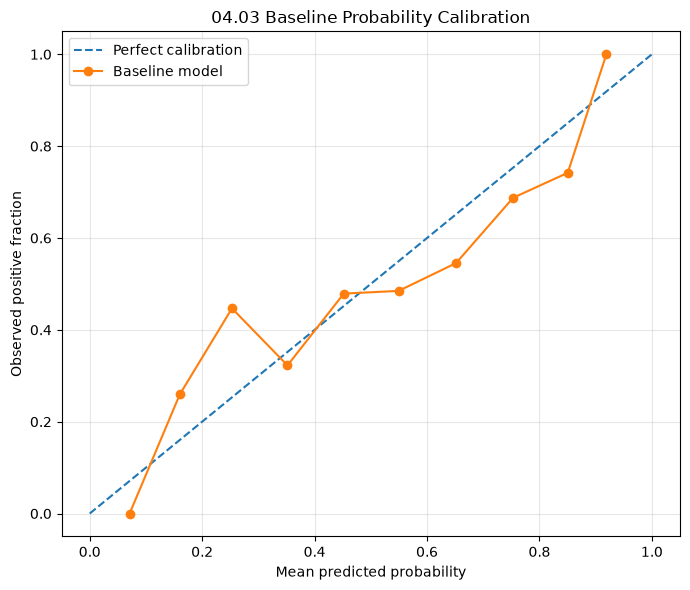


Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures\04_03_probability_calibration_curve.png
Calibration figure verification: PASSED


In [11]:
# ============================================================
# CELL 11 — CALIBRATION CURVE FIGURE
# ============================================================

calibration_figure_path = os.path.join(
    FIGURES_DIR,
    "04_03_probability_calibration_curve.png"
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="Baseline model"
)

plt.xlabel(
    "Mean predicted probability"
)

plt.ylabel(
    "Observed positive fraction"
)

plt.title(
    "04.03 Baseline Probability Calibration"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    calibration_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

assert os.path.exists(
    calibration_figure_path
)

print(
    "\nSaved:",
    calibration_figure_path
)

print("Calibration figure verification: PASSED")

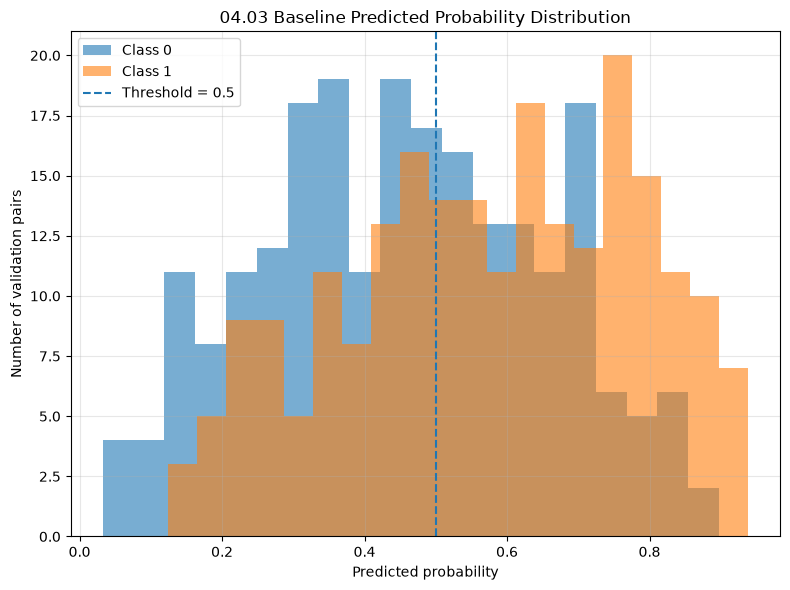


Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures\04_03_class_probability_distribution.png
Distribution figure verification: PASSED


In [12]:
# ============================================================
# CELL 12 — CLASS-WISE PROBABILITY DISTRIBUTION
# ============================================================

distribution_figure_path = os.path.join(
    FIGURES_DIR,
    "04_03_class_probability_distribution.png"
)

plt.figure(
    figsize=(8, 6)
)

plt.hist(
    class_0_probabilities,
    bins=20,
    alpha=0.6,
    label="Class 0"
)

plt.hist(
    class_1_probabilities,
    bins=20,
    alpha=0.6,
    label="Class 1"
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel(
    "Predicted probability"
)

plt.ylabel(
    "Number of validation pairs"
)

plt.title(
    "04.03 Baseline Predicted Probability Distribution"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    distribution_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

assert os.path.exists(
    distribution_figure_path
)

print(
    "\nSaved:",
    distribution_figure_path
)

print("Distribution figure verification: PASSED")

In [13]:
# ============================================================
# CELL 13 — SAVE PREDICTION-LEVEL PROBABILITY DATA
# ============================================================

prediction_analysis = validation_metadata.copy()

prediction_analysis[
    "logit"
] = logits

prediction_analysis[
    "predicted_probability"
] = probabilities

prediction_analysis[
    "predicted_class_at_0_5"
] = binary_predictions

prediction_analysis[
    "correct_at_0_5"
] = (
    binary_predictions
    ==
    labels.astype(int)
)

prediction_csv_path = os.path.join(
    REPORTS_DIR,
    "04_03_probability_predictions.csv"
)

prediction_analysis.to_csv(
    prediction_csv_path,
    index=False
)

print(
    prediction_analysis.head(10).to_string(
        index=False
    )
)

print(
    "\nSaved:",
    prediction_csv_path
)

assert len(prediction_analysis) == 448

assert (
    "predicted_probability"
    in prediction_analysis.columns
)

assert (
    "logit"
    in prediction_analysis.columns
)

assert (
    "predicted_class_at_0_5"
    in prediction_analysis.columns
)

assert os.path.exists(
    prediction_csv_path
)

print("\nPrediction-level artifact verification: PASSED")

source_modality target_modality  source_index  target_index  source_class  target_class  pair_label pair_type     logit  predicted_probability  predicted_class_at_0_5  correct_at_0_5
        Genetic      Behavioral            10           693             0             0           1  positive  0.201743               0.550265                       1            True
        Genetic      Behavioral            14           702             0             0           1  positive -1.208289               0.230004                       0           False
        Genetic      Behavioral            20           635             0             0           1  positive  0.048158               0.512037                       1            True
        Genetic      Behavioral             6           811             0             0           1  positive -1.454747               0.189272                       0           False
        Genetic      Behavioral            19           158             0            

In [14]:
# ============================================================
# CELL 14 — SAVE PROBABILITY ANALYSIS REPORT
# ============================================================

probability_report = {
    "phase": "04.03",
    "title": "Baseline Probability Analysis",

    "model": {
        "name": "BaselineCrossModalModel",
        "architecture": "128 -> 128 -> 64 -> 1",
        "input_dimension": 128,
        "parameters": 24833,
        "checkpoint_epoch": int(checkpoint_epoch),
        "checkpoint_roc_auc": float(checkpoint_auc)
    },

    "dataset": {
        "validation_samples": int(len(labels)),
        "class_0": int(np.sum(labels == 0)),
        "class_1": int(np.sum(labels == 1)),
        "embedding_dimension": 32
    },

    "overall_metrics": probability_metrics,

    "class_probability_summary": {
        "class_0": class_0_summary,
        "class_1": class_1_summary,
        "mean_probability_difference_class1_minus_class0":
            float(mean_probability_difference)
    },

    "quantiles": {
        "overall": overall_quantiles,
        "class_0": class_0_quantiles,
        "class_1": class_1_quantiles
    },

    "calibration": {
        "n_bins": 10,
        "mean_absolute_calibration_error":
            float(mean_calibration_error),
        "table":
            calibration_table.to_dict(
                orient="records"
            )
    },

    "artifacts": {
        "prediction_csv":
            prediction_csv_path,
        "calibration_figure":
            calibration_figure_path,
        "distribution_figure":
            distribution_figure_path
    }
}

probability_report_path = os.path.join(
    REPORTS_DIR,
    "04_03_probability_analysis_report.json"
)

with open(
    probability_report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        probability_report,
        file,
        indent=4
    )

print(
    "Saved:",
    probability_report_path
)

assert os.path.exists(
    probability_report_path
)

print("\nProbability report verification: PASSED")

Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_03_probability_analysis_report.json

Probability report verification: PASSED


In [15]:
# ============================================================
# CELL 15 — SAVE SUMMARY METRICS CSV
# ============================================================

summary_rows = [
    {
        "metric": metric_name,
        "value": metric_value
    }
    for metric_name, metric_value
    in probability_metrics.items()
]

summary_df = pd.DataFrame(
    summary_rows
)

summary_csv_path = os.path.join(
    REPORTS_DIR,
    "04_03_probability_metrics.csv"
)

summary_df.to_csv(
    summary_csv_path,
    index=False
)

print(
    summary_df.to_string(
        index=False
    )
)

print(
    "\nSaved:",
    summary_csv_path
)

assert os.path.exists(
    summary_csv_path
)

assert len(summary_df) == len(
    probability_metrics
)

print("\nSummary CSV verification: PASSED")

          metric    value
         roc_auc 0.662667
 accuracy_at_0_5 0.611607
precision_at_0_5 0.606838
   recall_at_0_5 0.633929
       f1_at_0_5 0.620087
     brier_score 0.234223
        log_loss 0.660638
mean_probability 0.515384
 std_probability 0.210515
 min_probability 0.032693
 max_probability 0.937904

Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_03_probability_metrics.csv

Summary CSV verification: PASSED


In [16]:
# ============================================================
# CELL 16 — FINAL VERIFICATION
# ============================================================

print("=" * 60)
print("04.03 FINAL VERIFICATION")
print("=" * 60)

print("\nValidation samples:")
print(f"    Total   : {len(labels)}")
print(f"    Class 0 : {np.sum(labels == 0)}")
print(f"    Class 1 : {np.sum(labels == 1)}")

print("\nProbability range:")
print(
    f"    Min : {probabilities.min():.10f}"
)

print(
    f"    Max : {probabilities.max():.10f}"
)

print(
    f"    Mean: {probabilities.mean():.10f}"
)

print("\nOverall probability metrics:")

print(
    f"    ROC-AUC              : {roc_auc:.10f}"
)

print(
    f"    Accuracy @ 0.5       : {accuracy:.10f}"
)

print(
    f"    Precision @ 0.5      : {precision:.10f}"
)

print(
    f"    Recall @ 0.5         : {recall:.10f}"
)

print(
    f"    F1 @ 0.5             : {f1:.10f}"
)

print(
    f"    Brier Score          : {brier:.10f}"
)

print(
    f"    Log Loss             : {logloss:.10f}"
)

print("\nClass-wise mean probabilities:")

print(
    f"    Class 0 : "
    f"{class_0_summary['mean']:.10f}"
)

print(
    f"    Class 1 : "
    f"{class_1_summary['mean']:.10f}"
)

print(
    f"    Difference: "
    f"{mean_probability_difference:.10f}"
)

print("\nCalibration:")
print(
    f"    Mean absolute calibration error: "
    f"{mean_calibration_error:.10f}"
)

print("\nArtifact verification:")

required_artifacts = [
    probability_report_path,
    summary_csv_path,
    prediction_csv_path,
    calibration_figure_path,
    distribution_figure_path
]

for artifact in required_artifacts:

    exists = os.path.exists(artifact)

    print(
        f"    {'PASSED' if exists else 'FAILED'} : "
        f"{artifact}"
    )

    assert exists


# Final numerical checks
assert len(labels) == 448
assert np.sum(labels == 0) == 224
assert np.sum(labels == 1) == 224

assert np.isfinite(probabilities).all()

assert np.all(
    (probabilities >= 0) &
    (probabilities <= 1)
)

assert abs(
    roc_auc - 0.6626674107142857
) < 1e-6

assert abs(
    probability_metrics["accuracy_at_0_5"]
    - 0.6116071428571429
) < 1e-6

assert abs(
    probability_metrics["f1_at_0_5"]
    - 0.6200873362445415
) < 1e-6

print("\nDataset verification: PASSED")
print("Probability range verification: PASSED")
print("Metric verification: PASSED")
print("Calibration verification: PASSED")
print("Artifact verification: PASSED")

print("\n" + "=" * 60)
print("04.03 PROBABILITY ANALYSIS: COMPLETE")
print("=" * 60)

04.03 FINAL VERIFICATION

Validation samples:
    Total   : 448
    Class 0 : 224
    Class 1 : 224

Probability range:
    Min : 0.0326929204
    Max : 0.9379035830
    Mean: 0.5153837204

Overall probability metrics:
    ROC-AUC              : 0.6626674107
    Accuracy @ 0.5       : 0.6116071429
    Precision @ 0.5      : 0.6068376068
    Recall @ 0.5         : 0.6339285714
    F1 @ 0.5             : 0.6200873362
    Brier Score          : 0.2342230529
    Log Loss             : 0.6606383324

Class-wise mean probabilities:
    Class 0 : 0.4550533295
    Class 1 : 0.5757140517
    Difference: 0.1206607223

Calibration:
    Mean absolute calibration error: 0.0845943422

Artifact verification:
    PASSED : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_03_probability_analysis_report.json
    PASSED : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_mo